## **EXAMEN SEGUNDO PARCIAL 02/2026 - Inteligencia Artificial I (SIS420)**
### **Ejercicio 1 - Aprendizaje No Supervisado**

**Nombre:** Plaza López Cesar Manuel

**Carrera:** Ingeniería de Sistemas

## **Extracción de parches y preparación del Dataset. -**

In [ ]:
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# HEIC
try:
    import pillow_heif
    pillow_heif.register_heif_opener()
except ImportError:
    pass

ruta_origen = "dataset_crudo"
ruta_salida = "dataset_parches_64x64"
archivo_npz = "dataset_quirpinchaca_64x64.npz"
patch_size = (64, 64)
max_parches_por_foto = 20

extensiones = ('.jpg', '.jpeg', '.png', '.bmp', '.heic', '.webp')
os.makedirs(ruta_salida, exist_ok=True)

rutas_fotos = []
for root, _, files in os.walk(ruta_origen):
    for f in files:
        if f.lower().endswith(extensiones):
            rutas_fotos.append(os.path.join(root, f))

print(f"Total de imágenes encontradas en '{ruta_origen}': {len(rutas_fotos)}")

parches = []
total_parches_guardados = 0

for i, path in enumerate(rutas_fotos):
    try:
        with Image.open(path) as img:
            img = img.convert('RGB')
            w, h = img.size
            
            if w < patch_size[0] or h < patch_size[1]:
                continue
            
            stride_x = max(patch_size[0], w // 5)
            stride_y = max(patch_size[1], h // 5)
            
            contador_foto = 0
            for top in range(0, h - patch_size[1] + 1, stride_y):
                for left in range(0, w - patch_size[0] + 1, stride_x):
                    if contador_foto >= max_parches_por_foto:
                        break
                    
                    box = (left, top, left + patch_size[0], top + patch_size[1])
                    patch = img.crop(box)
                    
                    # Guardar parche individual en disco
                    nombre_parche = f"parche_{total_parches_guardados:06d}.jpg"
                    patch.save(os.path.join(ruta_salida, nombre_parche), quality=95)
                    
                    parches.append(np.array(patch, dtype=np.uint8))
                    contador_foto += 1
                    total_parches_guardados += 1
    except Exception:
        continue
        
    if (i + 1) % 50 == 0 or (i + 1) == len(rutas_fotos):
        print(f"Fotos procesadas: {i + 1}/{len(rutas_fotos)} | Parches generados: {total_parches_guardados}")


X_raw = np.array(parches, dtype=np.uint8)
np.savez_compressed(archivo_npz, X=X_raw)

print(f"\nDataset listo:")
print(f"Forma de X_raw: {X_raw.shape} (N_muestras, Alto, Ancho, Canales)")

Total de imágenes encontradas en 'dataset_crudo': 566
Fotos procesadas: 50/566 | Parches generados: 1000
Fotos procesadas: 100/566 | Parches generados: 2000
Fotos procesadas: 150/566 | Parches generados: 3000
Fotos procesadas: 200/566 | Parches generados: 4000
Fotos procesadas: 250/566 | Parches generados: 5000
Fotos procesadas: 300/566 | Parches generados: 6000
Fotos procesadas: 350/566 | Parches generados: 7000
Fotos procesadas: 400/566 | Parches generados: 8000
Fotos procesadas: 450/566 | Parches generados: 9000
Fotos procesadas: 500/566 | Parches generados: 10000
Fotos procesadas: 550/566 | Parches generados: 11000
Fotos procesadas: 566/566 | Parches generados: 11320

Dataset listo:
Forma de X_raw: (11320, 64, 64, 3) (N_muestras, Alto, Ancho, Canales)


## **Inspección visual de los parches. -**

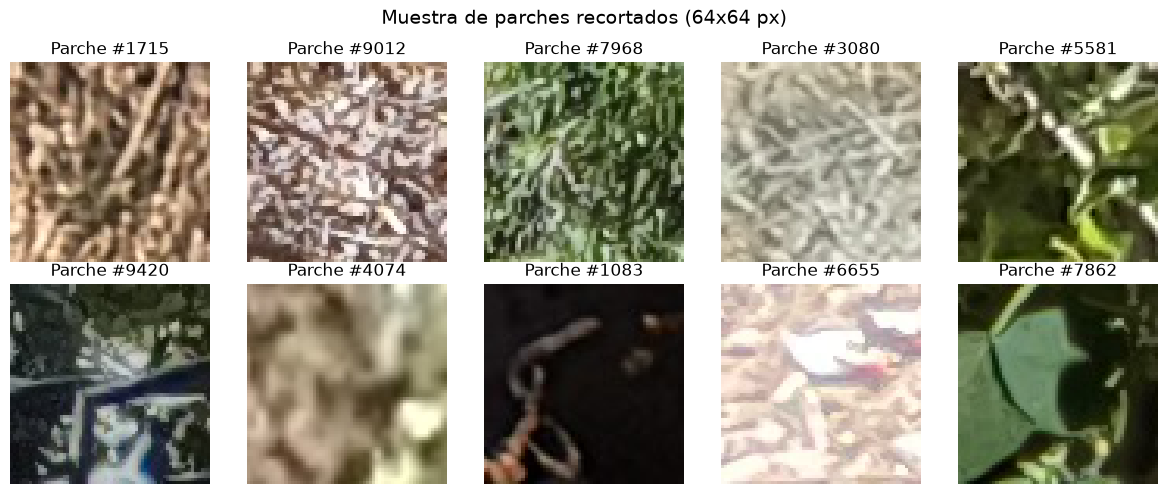

In [ ]:

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
indices = np.random.choice(len(X_raw), 10, replace=False)

for ax, idx in zip(axes.ravel(), indices):
    ax.imshow(X_raw[idx])
    ax.axis('off')
    ax.set_title(f"Parche #{idx}")

plt.suptitle("Muestra de parches recortados (64x64 px)", fontsize=14)
plt.tight_layout()
plt.show()

In [1]:
import numpy as np

datos = np.load("dataset_quirpinchaca_64x64.npz")
X_raw = datos['X']

print(f"Dataset cargado con éxito. Dimensiones de X_raw: {X_raw.shape}")

Dataset cargado con éxito. Dimensiones de X_raw: (11320, 64, 64, 3)


## **Aplanado, normalización y entrenamiento de K-Means. -**


Dimensiones de X para Scikit-Learn: (11320, 12288)

Se encontraron los 20 parches más representativos (uno por centroide).
Índices de las imágenes representativas en el dataset: [ 3093  5165  3728  2789  5716  2798 10180  7595  6265  9798  6255  1102
  6583  3135  6524  4508  5704  7649  7735  5186]


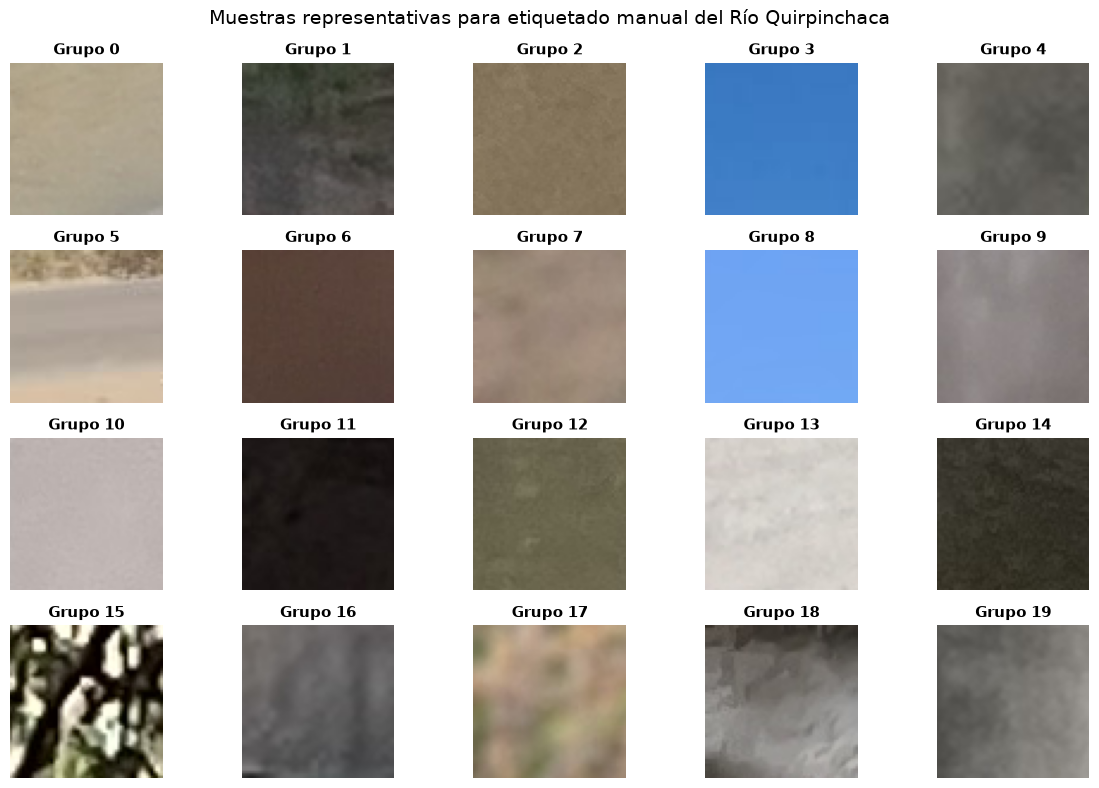

In [2]:
from sklearn.cluster import KMeans
import numpy as np
import matplotlib.pyplot as plt

X = X_raw.reshape(X_raw.shape[0], -1).astype("float32") / 255.0
print(f"Dimensiones de X para Scikit-Learn: {X.shape}")

k = 20
kmeans = KMeans(n_clusters=k, init="k-means++", n_init=10, max_iter=300, random_state=42)


X_distancias = kmeans.fit_transform(X)



idx_representativos = np.argmin(X_distancias, axis=0)


X_representativos = X_raw[idx_representativos]

print(f"\nSe encontraron los 20 parches más representativos (uno por centroide).")
print(f"Índices de las imágenes representativas en el dataset: {idx_representativos}")


plt.figure(figsize=(12, 8))
for i in range(k):
    plt.subplot(4, 5, i + 1)
    plt.imshow(X_representativos[i])
    plt.title(f"Grupo {i}", fontsize=11, fontweight="bold")
    plt.axis("off")

plt.suptitle("Muestras representativas para etiquetado manual del Río Quirpinchaca", fontsize=14)
plt.tight_layout()
plt.show()

### **Array de etiquetas asignadas manualmente por inspección visual de las 20 muestras.-**

Convención: 0: Vegetación | 1: Suelo/Paja | 2: Basura/Plásticos (Alta Reflectancia) | 3: Sombra/Barro

In [3]:
y_manual_representativos = np.array([
    1, 1, 1, 2, 3,  
    1, 3, 1, 2, 1,  
    2, 3, 0, 2, 0, 
    0, 3, 0, 2, 3   
], dtype=np.int64)


y_propagado = np.empty(len(X), dtype=np.int64)


for i in range(k):
    y_propagado[kmeans.labels_ == i] = y_manual_representativos[i]


nombres_clases = ["Vegetación", "Suelo/Paja", "Basura/Plásticos", "Sombra/Barro"]
print("Propagación de etiquetas finalizada con éxito.")
print("Distribución total de parches etiquetados en el dataset:")
for c, nombre in enumerate(nombres_clases):
    total = np.sum(y_propagado == c)
    porcentaje = (total / len(y_propagado)) * 100
    print(f"  Clase {c} ({nombre}): {total} parches ({porcentaje:.2f}%)")

Propagación de etiquetas finalizada con éxito.
Distribución total de parches etiquetados en el dataset:
  Clase 0 (Vegetación): 2459 parches (21.72%)
  Clase 1 (Suelo/Paja): 3913 parches (34.57%)
  Clase 2 (Basura/Plásticos): 1645 parches (14.53%)
  Clase 3 (Sombra/Barro): 3303 parches (29.18%)


## **Silhouette Score. -**

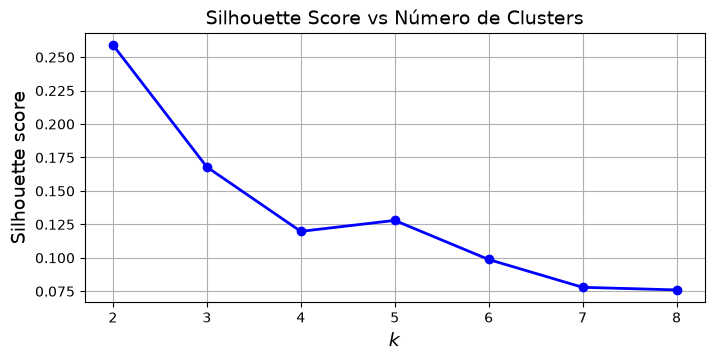

In [ ]:
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt


np.random.seed(42)
idx_sub = np.random.choice(len(X), 3000, replace=False)
X_sub = X[idx_sub]


max_k = 8
ks = list(range(2, max_k + 1))


kmeans_per_k = [KMeans(n_clusters=k, init="k-means++", n_init=5, random_state=42).fit(X_sub) for k in range(1, max_k + 1)]


silhouette_scores = [silhouette_score(X_sub, model.labels_) for model in kmeans_per_k[1:]]

# 3. Graficar la curva de silueta
plt.figure(figsize=(8, 3.5))
plt.plot(ks, silhouette_scores, "bo-", linewidth=2)
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Silhouette score", fontsize=14)
plt.title("Silhouette Score vs Número de Clusters", fontsize=14)
plt.grid(True)
plt.show()

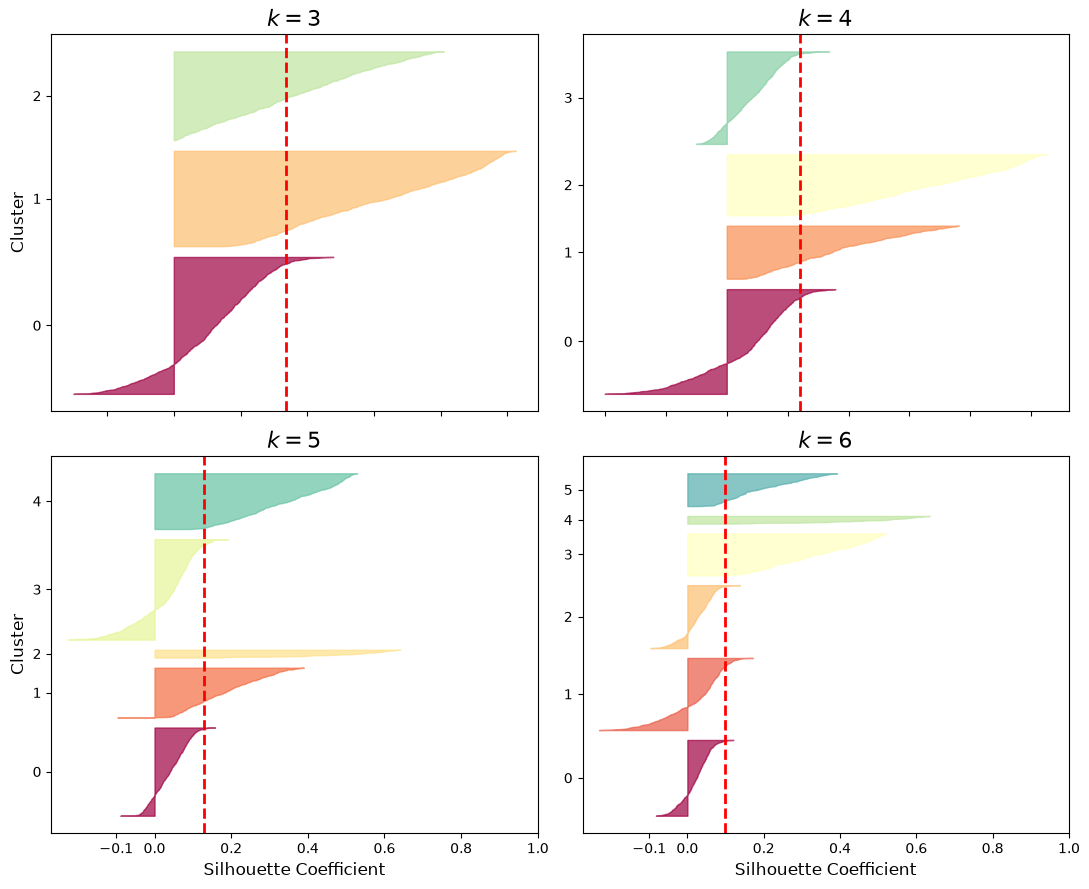

In [7]:
from sklearn.metrics import silhouette_samples
from matplotlib.ticker import FixedLocator, FixedFormatter
import matplotlib as mpl

plt.figure(figsize=(11, 9))

valid_ks = [k for k in (3, 4, 5, 6) if k <= len(kmeans_per_k)]

for plot_idx, k in enumerate(valid_ks):
    plt.subplot(2, 2, plot_idx + 1)

    y_pred_k = kmeans_per_k[k - 1].labels_
    silhouette_coefficients = silhouette_samples(X_sub, y_pred_k)

    padding = len(X_sub) // 30
    pos = padding
    ticks = []
    
    for i in range(k):
        coeffs = silhouette_coefficients[y_pred_k == i]
        coeffs.sort()

        color = mpl.cm.Spectral(i / k)
        plt.fill_betweenx(np.arange(pos, pos + len(coeffs)), 0, coeffs,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos + len(coeffs) // 2)
        pos += len(coeffs) + padding

    plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
    plt.gca().yaxis.set_major_formatter(FixedFormatter(range(k)))
    
    if k in (3, 5):
        plt.ylabel("Cluster", fontsize=12)

    if k in (5, 6):
        plt.gca().set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
        plt.xlabel("Silhouette Coefficient", fontsize=12)
    else:
        plt.tick_params(labelbottom=False)

    # Línea vertical roja con el promedio del coeficiente de silueta
    if k - 2 < len(silhouette_scores):
        plt.axvline(x=silhouette_scores[k - 2], color="red", linestyle="--", linewidth=2)
        
    plt.title(f"$k={k}$", fontsize=16)

plt.tight_layout()
plt.show()

## **Clasificador Multiclase y Métricas Finales. -**

Entrenando Red Neuronal sobre etiquetas propagadas...
Epoch  1/25 | Loss promedio: 1.4342
Epoch  5/25 | Loss promedio: 1.0888
Epoch 10/25 | Loss promedio: 1.0104
Epoch 15/25 | Loss promedio: 0.9757
Epoch 20/25 | Loss promedio: 0.9210
Epoch 25/25 | Loss promedio: 0.9041

EXACTITUD (Accuracy) TRAS PROPAGACIÓN: 53.00%

Reporte de Clasificación:
                  precision    recall  f1-score   support

      Vegetación       0.46      0.29      0.36       492
      Suelo/Paja       0.52      0.90      0.66       782
Basura/Plásticos       0.76      0.18      0.29       329
    Sombra/Barro       0.56      0.44      0.50       661

        accuracy                           0.53      2264
       macro avg       0.57      0.45      0.45      2264
    weighted avg       0.55      0.53      0.49      2264



<Figure size 700x600 with 0 Axes>

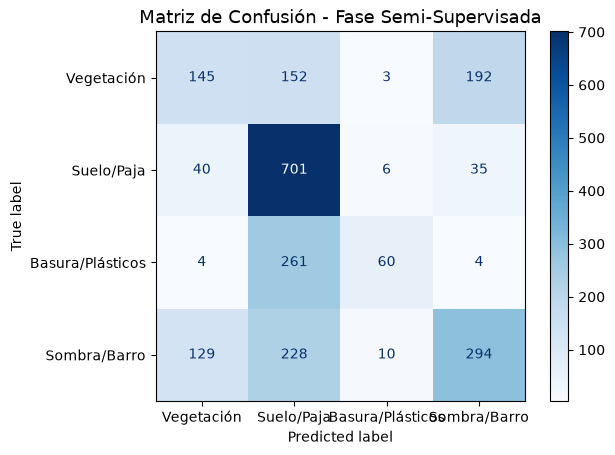

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay


X_train, X_test, y_train, y_test = train_test_split(
    X, y_propagado, test_size=0.2, random_state=42, stratify=y_propagado
)

device = torch.device("cpu")

X_t = torch.from_numpy(X_train).float().to(device)
Y_t = torch.from_numpy(y_train).long().to(device)

X_test_t = torch.from_numpy(X_test).float().to(device)
Y_test_t = torch.from_numpy(y_test).long().to(device)


batch_size = 128
train_dataset = TensorDataset(X_t, Y_t)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)


D_in = 64 * 64 * 3   # 12,288
H = 128
D_out = 4

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(D_in, H),
    nn.ReLU(),
    nn.Dropout(p=0.2),
    nn.Linear(H, D_out)
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)


epochs = 25
historial_loss = []

print("Entrenando Red Neuronal sobre etiquetas propagadas...")
for e in range(1, epochs + 1):
    model.train()
    running_loss = 0.0
    
    for x_batch, y_batch in train_loader:
        optimizer.zero_grad()
        y_logits = model(x_batch)
        loss = criterion(y_logits, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(y_batch)
        
    epoch_loss = running_loss / len(X_train)
    historial_loss.append(epoch_loss)
    
    if e % 5 == 0 or e == 1:
        print(f"Epoch {e:2d}/{epochs} | Loss promedio: {epoch_loss:.4f}")

# 5. Evaluación en el conjunto de prueba
model.eval()
with torch.no_grad():
    y_test_logits = model(X_test_t)
    y_pred_test = torch.argmax(y_test_logits, dim=1).cpu().numpy()

# 6. Reporte de Métricas
nombres_clases = ["Vegetación", "Suelo/Paja", "Basura/Plásticos", "Sombra/Barro"]
acc = accuracy_score(y_test, y_pred_test)

print("\n" + "="*55)
print(f"EXACTITUD (Accuracy) TRAS PROPAGACIÓN: {acc * 100:.2f}%")
print("="*55)
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred_test, target_names=nombres_clases))

# 7. Matriz de Confusión
cm = confusion_matrix(y_test, y_pred_test)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nombres_clases)

plt.figure(figsize=(7, 6))
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de Confusión - Fase Semi-Supervisada", fontsize=13)
plt.grid(False)
plt.show()

## **Aprendizaje Activo. -**

Rango de confianza en las 15 muestras más dudosas: 27.0% - 28.1%


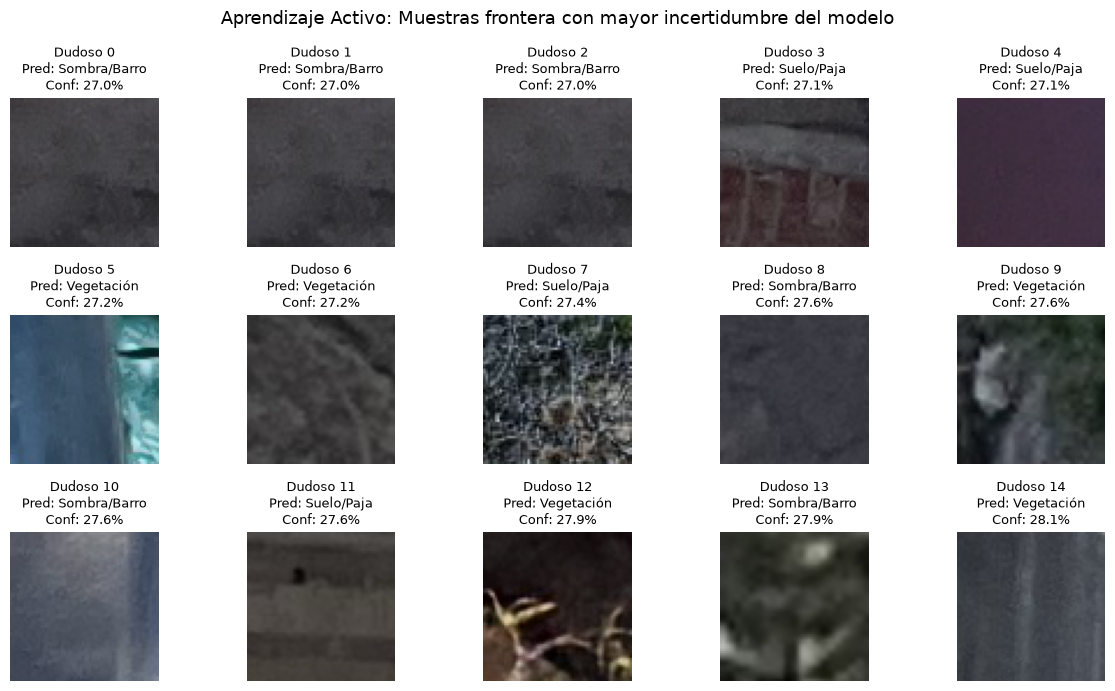

In [ ]:
import torch.nn.functional as F

model.eval()
with torch.no_grad():
    logits_train = model(X_t)
    probs_train = F.softmax(logits_train, dim=1).cpu().numpy()


max_probs = np.max(probs_train, axis=1)


n_activos = 15
idx_dudosos = np.argsort(max_probs)[:n_activos]

print(f"Rango de confianza en las {n_activos} muestras más dudosas: "
      f"{max_probs[idx_dudosos[0]]*100:.1f}% - {max_probs[idx_dudosos[-1]]*100:.1f}%")


plt.figure(figsize=(12, 7))
for i, idx in enumerate(idx_dudosos):
    plt.subplot(3, 5, i + 1)
    img_dudosa = (X_train[idx].reshape(64, 64, 3) * 255).astype(np.uint8)
    clase_pred = np.argmax(probs_train[idx])
    confianza = max_probs[idx] * 100
    
    plt.imshow(img_dudosa)
    plt.title(f"Dudoso {i}\nPred: {nombres_clases[clase_pred]}\nConf: {confianza:.1f}%", fontsize=9)
    plt.axis("off")

plt.suptitle("Aprendizaje Activo: Muestras frontera con mayor incertidumbre del modelo", fontsize=13)
plt.tight_layout()
plt.show()

In [6]:

y_corregidas_activas = np.array([
    3, 3, 3, 3, 3, 
    2, 3, 1, 3, 0,  
    2, 1, 0, 0, 3  
], dtype=np.int64)


Y_t_activo = Y_t.clone()
Y_t_activo[idx_dudosos] = torch.from_numpy(y_corregidas_activas).to(device)


train_dataset_activo = TensorDataset(X_t, Y_t_activo)
train_loader_activo = DataLoader(train_dataset_activo, batch_size=batch_size, shuffle=True)


epochs_activas = 10
print("Reentrenando modelo tras intervención humana (Aprendizaje Activo)...")

for e in range(1, epochs_activas + 1):
    model.train()
    running_loss = 0.0
    
    for x_batch, y_batch in train_loader_activo:
        optimizer.zero_grad()
        y_logits = model(x_batch)
        loss = criterion(y_logits, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(y_batch)
        
    epoch_loss = running_loss / len(X_train)
    if e % 5 == 0 or e == 1:
        print(f"Epoch Activa {e:2d}/{epochs_activas} | Loss promedio: {epoch_loss:.4f}")


model.eval()
with torch.no_grad():
    y_test_logits_final = model(X_test_t)
    y_pred_test_final = torch.argmax(y_test_logits_final, dim=1).cpu().numpy()

acc_final = accuracy_score(y_test, y_pred_test_final)

print("\n" + "="*55)
print(f"EXACTITUD (Accuracy) TRAS APRENDIZAJE ACTIVO: {acc_final * 100:.2f}%")
print("="*55)
print("\nReporte de Clasificación Final:")
print(classification_report(y_test, y_pred_test_final, target_names=nombres_clases))

Reentrenando modelo tras intervención humana (Aprendizaje Activo)...
Epoch Activa  1/10 | Loss promedio: 0.8973
Epoch Activa  5/10 | Loss promedio: 0.8707
Epoch Activa 10/10 | Loss promedio: 0.8563

EXACTITUD (Accuracy) TRAS APRENDIZAJE ACTIVO: 57.77%

Reporte de Clasificación Final:
                  precision    recall  f1-score   support

      Vegetación       0.42      0.25      0.31       492
      Suelo/Paja       0.65      0.71      0.68       782
Basura/Plásticos       0.68      0.62      0.65       329
    Sombra/Barro       0.52      0.65      0.58       661

        accuracy                           0.58      2264
       macro avg       0.57      0.56      0.55      2264
    weighted avg       0.57      0.58      0.56      2264

